# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ShayanAhmed12/flyrank-internship-ml/blob/main/work/notebooks/w07_action_playbook.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

**What this playbook ranks:** visible pages (positions 1–20, ≥500 impressions in the last 15 days) whose CTR is well below what pages at a similar position get, ordered by **clicks at stake**. It's the frozen Week-4 rule, validated in ML-08 (5 client-grouped folds, P@50 ≈ 0.78) and ML-09 (frozen March → scored April, 44/50).

**Decision day for this queue:** **2026-04-16** (features from 1–15 April). It's the latest month I validated; June 2026 stays sealed. The Random Forest from ML-08 (trained on March) is attached as a **second opinion**, not as the ranking.

**Archetype → action map.** Each flagged page gets exactly one archetype (first match wins), one reason code, and one action:

| # | Archetype | Rule (feature window only) | Reason code | Action |
|---|---|---|---|---|
| A | **Broad-query mismatch** | ≥20k impressions and CTR < 25% of expected | `huge_exposure_tiny_ctr` | `review_search_intent`: check which queries drive the impressions; re-target or accept |
| B | **Top-3 zero-click risk** | position ≤ 3 and informational intent | `top3_low_ctr_informational` | `check_serp_then_monitor`: look at the live SERP for answer boxes/AI overviews before touching the page |
| C | **Page-one snippet gap** | position 4–10 | `page1_low_ctr_for_position` | `review_title_meta`: rewrite title + meta, sharpen the promise to the query |
| D | **Striking-distance gap** | position 11–20 | `page2_low_ctr_for_position` | `improve_relevance`: on-page relevance and internal links; a snippet won't help much on page 2 |
| E | **Top-3 snippet gap** | position ≤ 3, non-informational intent | `top3_low_ctr_for_position` | `review_title_meta` (highest priority: biggest CTR upside per impression) |
| M | **Model-only watch** | not flagged by the rule, but Random Forest probability in the top 5% of the pool | `model_flag_only` | `monitor`: no edit, re-check next cycle |

**Decay / refresh insight** (cell below): I check whether under-capturing is related to **page age**. This is the "refresh" angle from the paper's lifecycle findings, measured on my label and on the next fortnight, not the same snapshot.


In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, sys, json, subprocess, duckdb, numpy as np, pandas as pd, sklearn
import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download, get_token
from sklearn.ensemble import RandomForestClassifier
from IPython.display import Image, display

if "google.colab" in sys.modules:
    if not os.path.isdir("flyrank-ml-internship-starter"):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/flyrank-bih/flyrank-ml-internship-starter"], check=True)
    os.chdir("flyrank-ml-internship-starter")
else:
    while not os.path.isdir("work") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")
os.makedirs("work/outputs", exist_ok=True); os.makedirs("work/figures", exist_ok=True)

SEED = 42
assert get_token(), "No Hugging Face token: log in (hf auth login) or add HF_TOKEN in Colab Secrets"
REPO = "FlyRank/internship-warehouse"
con = duckdb.connect()
con.execute(f"CREATE VIEW dim_content AS SELECT * FROM read_parquet('{hf_hub_download(REPO, 'dim_content.parquet', repo_type='dataset')}')")
for m in ("2026-03", "2026-04"):
    con.execute(f"CREATE VIEW fact_{m.replace('-', '_')} AS SELECT * FROM read_parquet('{hf_hub_download(REPO, f'fact_content_daily_performance/month={m}/data_0.parquet', repo_type='dataset')}')")

def build_frame(month, decision):
    t = f"fact_{month.replace('-', '_')}"
    df = con.sql(f"""
        WITH f AS (SELECT client_hash_id, content_hash_id,
                          SUM(gsc_impressions) AS impr_f, SUM(gsc_clicks) AS clicks_f,
                          SUM(gsc_avg_position * gsc_impressions) / NULLIF(SUM(gsc_impressions), 0) AS pos_f
                   FROM {t} WHERE gsc_data_available IS TRUE AND report_date <  DATE '{decision}' GROUP BY 1, 2),
             o AS (SELECT content_hash_id, SUM(gsc_impressions) AS impr_o, SUM(gsc_clicks) AS clicks_o
                   FROM {t} WHERE gsc_data_available IS TRUE AND report_date >= DATE '{decision}' GROUP BY 1)
        SELECT f.client_hash_id, f.content_hash_id, f.impr_f, f.clicks_f,
               100.0 * f.clicks_f / f.impr_f AS ctr_f, f.pos_f, c.content_type, c.main_intent,
               DATE_DIFF('day', c.content_created_date, DATE '{decision}') AS age_days,
               o.impr_o, 100.0 * o.clicks_o / o.impr_o AS ctr_o
        FROM f JOIN o USING (content_hash_id) LEFT JOIN dim_content c USING (content_hash_id)
        WHERE f.impr_f >= 100 AND o.impr_o >= 100 AND f.pos_f BETWEEN 1 AND 20
    """).df().sort_values("content_hash_id").reset_index(drop=True)
    df["pos_bucket"] = pd.cut(df["pos_f"], [0, 3, 10, 20], labels=["1-3", "4-10", "11-20"])
    df["under_captures_next"] = (df["ctr_o"] < 0.5 * df.groupby("pos_bucket", observed=True)["ctr_o"].transform("median")).astype(int)
    df["expected_ctr"] = df.groupby("pos_bucket", observed=True)["ctr_f"].transform("median")
    df["ctr_ratio_f"] = df["ctr_f"] / df["expected_ctr"]
    df["log_impr_f"] = np.log1p(df["impr_f"])
    df["rule_flag"] = (df["impr_f"] >= 500) & (df["ctr_ratio_f"] < 0.5)
    df["clicks_at_stake"] = np.where(df["rule_flag"], (df["expected_ctr"] - df["ctr_f"]) / 100 * df["impr_f"], 0.0)
    return df

mar = build_frame("2026-03", "2026-03-16")
apr = build_frame("2026-04", "2026-04-16")

# Second opinion: Random Forest trained on March only (ML-08 settings), scored on April
NUM = ["log_impr_f", "ctr_f", "pos_f", "age_days", "expected_ctr", "ctr_ratio_f"]
TYPES = sorted(mar["content_type"].dropna().unique())
def X_of(d):
    X = d[NUM].copy(); X["age_days"] = X["age_days"].fillna(mar["age_days"].median())
    for t in TYPES: X[f"type_{t}"] = (d["content_type"] == t).astype(float)
    return X
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=50, n_jobs=-1, random_state=SEED).fit(X_of(mar), mar["under_captures_next"])
apr["model_prob"] = rf.predict_proba(X_of(apr))[:, 1]

# Archetypes (first match wins) - feature-window inputs only
pool = apr["impr_f"] >= 500
model_cut = apr.loc[pool & ~apr["rule_flag"], "model_prob"].quantile(0.95)   # top 5% of pages the rule did NOT flag
intent = apr["main_intent"].fillna("").str.lower()
conds = [
    apr["rule_flag"] & (apr["impr_f"] >= 20000) & (apr["ctr_ratio_f"] < 0.25),
    apr["rule_flag"] & (apr["pos_f"] <= 3) & (intent == "informational"),
    apr["rule_flag"] & apr["pos_f"].between(3, 10, inclusive="right"),
    apr["rule_flag"] & (apr["pos_f"] > 10),
    apr["rule_flag"] & (apr["pos_f"] <= 3),
    ~apr["rule_flag"] & pool & (apr["model_prob"] >= model_cut),
]
ARCH = [("A broad-query mismatch", "huge_exposure_tiny_ctr", "review_search_intent"),
        ("B top-3 zero-click risk", "top3_low_ctr_informational", "check_serp_then_monitor"),
        ("C page-one snippet gap", "page1_low_ctr_for_position", "review_title_meta"),
        ("D striking-distance gap", "page2_low_ctr_for_position", "improve_relevance"),
        ("E top-3 snippet gap", "top3_low_ctr_for_position", "review_title_meta"),
        ("M model-only watch", "model_flag_only", "monitor")]
apr["archetype"] = np.select(conds, [a[0] for a in ARCH], default="")
apr["reason_code"] = np.select(conds, [a[1] for a in ARCH], default="")
apr["action"] = np.select(conds, [a[2] for a in ARCH], default="no_action")

queue = (apr[apr["action"] != "no_action"]
         .sort_values(["rule_flag", "clicks_at_stake", "model_prob"], ascending=[False, False, False])
         .reset_index(drop=True).assign(rank=lambda d: d.index + 1))
queue["second_opinion"] = np.where(queue["model_prob"] >= 0.6, "model agrees", "model unsure")

summary = queue.groupby(["archetype", "action"]).agg(pages=("rank", "size"), clicks_at_stake_15d=("clicks_at_stake", "sum"),
                                                     model_agrees=("second_opinion", lambda s: (s == "model agrees").mean()))
print(f"Decision day 2026-04-16 | queue: {len(queue):,} pages ({int(queue['rule_flag'].sum()):,} rule-flagged + "
      f"{int((~queue['rule_flag']).sum()):,} model-only watch) from {queue['client_hash_id'].nunique()} clients")
print(summary.round(2).to_string())
print("\nTop 10 of the queue:")
print(queue.head(10)[["rank", "archetype", "reason_code", "action", "pos_f", "impr_f", "ctr_f", "expected_ctr",
                      "clicks_at_stake", "second_opinion"]].round(3).to_string(index=False))


Decision day 2026-04-16 | queue: 11,823 pages (10,454 rule-flagged + 1,369 model-only watch) from 37 clients
                                                 pages  clicks_at_stake_15d  model_agrees
archetype               action                                                           
A broad-query mismatch  review_search_intent        49              2598.21          1.00
B top-3 zero-click risk check_serp_then_monitor   1033              3889.39          0.53
C page-one snippet gap  review_title_meta         6726             20767.44          0.40
D striking-distance gap improve_relevance         1959               785.34          0.26
E top-3 snippet gap     review_title_meta          687              2198.69          0.40
M model-only watch      monitor                   1369                 0.00          0.00

Top 10 of the queue:
 rank              archetype                reason_code               action  pos_f   impr_f  ctr_f  expected_ctr  clicks_at_stake second_opinion
   

### Decay / refresh insight

Base rate 0.410
                n  under_capture_rate  median_ctr_ratio
age_bucket                                             
0-90d       20402               0.376             1.217
91-180d      9118               0.474             0.686
181-270d    12567               0.437             0.872
271-365d     9333               0.371             1.186
365d+        8112               0.424             0.821


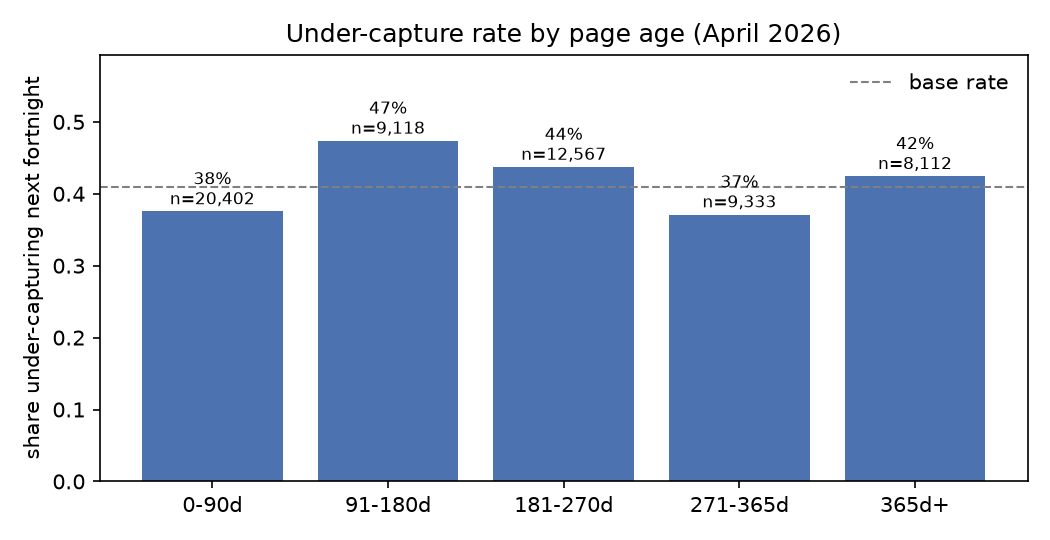

In [2]:
# Is under-capturing related to page age? (April, all lane pages, outcome = next fortnight)
apr["age_bucket"] = pd.cut(apr["age_days"], [-1, 90, 180, 270, 365, 10_000], labels=["0-90d", "91-180d", "181-270d", "271-365d", "365d+"])
decay = apr.groupby("age_bucket", observed=True).agg(n=("under_captures_next", "size"),
                                                     under_capture_rate=("under_captures_next", "mean"),
                                                     median_ctr_ratio=("ctr_ratio_f", "median"))
print(f"Base rate {apr['under_captures_next'].mean():.3f}")
print(decay.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(decay.index.astype(str), decay["under_capture_rate"], color="#4C72B0")
ax.axhline(apr["under_captures_next"].mean(), ls="--", color="grey", lw=1, label="base rate")
for i, (r, n) in enumerate(zip(decay["under_capture_rate"], decay["n"])):
    ax.text(i, r + 0.01, f"{r:.0%}\nn={n:,}", ha="center", fontsize=8)
ax.set_ylabel("share under-capturing next fortnight"); ax.set_title("Under-capture rate by page age (April 2026)")
ax.set_ylim(0, max(decay["under_capture_rate"]) + 0.12); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig("work/figures/w07_decay_by_age.png", dpi=150); plt.close(fig)
display(Image("work/figures/w07_decay_by_age.png"))


**Decay / refresh insight: MIXED, and weaker than the lifecycle story suggests.** Page age is **not** a clean driver of under-capturing in my lane. The rate goes 38% (0–90 days) → **47% (91–180 days, the peak)** → 44% → 37% (271–365 days) → 42% (365+), against a 41% base rate. Every bucket has n > 8,000. The 91–180-day bucket also has the lowest median CTR ratio (0.69), so the signal is that **mid-life pages (3–6 months) are the most likely to under-click for their position**. That's not the 9–12-month decay cliff the paper describes for *health score*.

**What it means for the playbook:** I don't add an age rule. The CTR gap already captures what matters, and an age filter would mostly add noise. It *does* suggest a light habit: when a page turns ~3 months old, give its title/meta one look, because that's when the original snippet often stops matching how the page actually ranks. This is **directional and observational** (one month, one label); it isn't evidence that refreshing at 3 months causes anything.

## 2. Intended use and limits

**Intended use:** a **weekly review list for an SEO/content editor**. Each cycle, the editor works from the top of the queue for as many pages as they have hours (realistically 20–50), does the archetype's action **after a human check**, and logs what they did. It's **decision support**: it says where to look first, not what is broken.

**Who it's for:** editors/SEO leads on sites in the same kind of portfolio (keyword-article heavy, Search Console connected). **Not** for: automated publishing tools, client-facing performance claims, or deciding which pages to delete.

**Cost / value thinking** (cell below), under openly rough assumptions:
- Cost of one review ≈ **30–45 min** of editor time. A false positive wastes that, plus the small risk of degrading a title that was fine.
- Value ≈ the clicks the page is missing **if** it moved to the typical CTR for its position. That's an *upper bound*, not a forecast: the fix might not work, and part of the gap is SERP layout nobody can change.
- With measured precision at the top of ~0.78 (5-fold) to 0.88 (April), roughly 1 in 5 top picks is a wasted review. That's acceptable if each real hit is worth more than ~1 hour of time, which it mostly is near the top of the list and stops being true further down.

**Where it stops being valid:**
- Pages with <500 impressions in the window (too noisy, too little at stake), positions >20, pages without Search Console data.
- Sites unlike the training portfolio (e.g. e-commerce category pages, news). Validation covered 36–43 clients over March–April 2026 only.
- Any claim of **cause**: the data can't show that a rewrite *produces* more clicks (ML-09 claim rewrite).
- Periods right after a Google core update, or a site migration, when CTR and positions move for reasons unrelated to the page.


In [3]:
# Cost/value: how many clicks are at stake at different queue depths, and what does that cost in editor time?
rule_q = queue[queue["rule_flag"]]
rows = []
for k in (20, 50, 100, 250):
    top = rule_q.head(k)
    hit = top["under_captures_next"].mean()                         # receipt: observed next-fortnight precision
    stake = top["clicks_at_stake"].sum()
    rows.append({"top_k": k, "editor_hours (@40 min)": round(k * 40 / 60, 1), "observed precision": round(hit, 3),
                 "clicks_at_stake_15d (upper bound)": int(stake),
                 "upper-bound clicks per editor hour": round(stake * hit / (k * 40 / 60), 1)})
cv = pd.DataFrame(rows)
print(cv.to_string(index=False))
print("\nRead: value per hour falls quickly down the list, so the queue depth should follow editor capacity, not 'all flagged pages'.")


 top_k  editor_hours (@40 min)  observed precision  clicks_at_stake_15d (upper bound)  upper-bound clicks per editor hour
    20                    13.3               0.900                               1666                               112.5
    50                    33.3               0.880                               2869                                75.8
   100                    66.7               0.920                               4224                                58.3
   250                   166.7               0.852                               6925                                35.4

Read: value per hour falls quickly down the list, so the queue depth should follow editor capacity, not 'all flagged pages'.


## 3. Human review + the no-go list

**Before acting on any queued page, a person checks:**
1. **Open the live search results** for the page's main query: is there an answer box, AI overview, video carousel or ads block taking the clicks? If yes → `monitor`, don't rewrite. (Required for archetypes **A** and **B**.)
2. **Read the current title and meta** against the query intent. Rewrite only if the promise is unclear, generic or mismatched.
3. **Check the page wasn't changed in the last 30 days**: a recent edit may already be working through.
4. **Check concentration:** if one site owns a large share of the queue (it did: up to ~30–40% in ML-07/09), review a few of its pages first to spot a site-wide template issue. One template fix beats 20 page edits.
5. **Log** page, action, date and the before-CTR, so the next cycle can measure what happened.

**No-go list (never automate):**
- ❌ **Auto-rewriting titles/metas** (including with an LLM) and publishing without a human reading the SERP and the page.
- ❌ **Deleting, noindexing or redirecting** pages because they rank in this queue. Low CTR isn't low value.
- ❌ **Changing a client's site-wide templates** from model output alone.
- ❌ **Reporting "clicks at stake" as expected gains** to clients or management. It's an upper bound for prioritising, not a forecast.
- ❌ **Using the model-only watch list (M) for edits.** It's a "look again next cycle" list; the model never beat the rule at the top.
- ❌ **Acting on pages with <500 impressions** or on the bottom of the queue just because they're flagged.


In [4]:
# The review checklist travels with every queued row
CHECK = {
    "review_search_intent": "SERP + query mix check; re-target or accept",
    "check_serp_then_monitor": "SERP check REQUIRED; edit only if no SERP feature explains the gap",
    "review_title_meta": "read title/meta vs intent; rewrite only if unclear; log before-CTR",
    "improve_relevance": "on-page relevance + internal links; no snippet-only change",
    "monitor": "no edit; re-check next cycle",
}
queue["human_check"] = queue["action"].map(CHECK)
queue["automate"] = "never"
print(queue[["action", "human_check", "automate"]].drop_duplicates("action").to_string(index=False))


                 action                                                        human_check automate
   review_search_intent                        SERP + query mix check; re-target or accept    never
      review_title_meta read title/meta vs intent; rewrite only if unclear; log before-CTR    never
check_serp_then_monitor SERP check REQUIRED; edit only if no SERP feature explains the gap    never
      improve_relevance         on-page relevance + internal links; no snippet-only change    never
                monitor                                       no edit; re-check next cycle    never


## 4. Monitoring / retrain triggers

Run a light check **once a month** on the newest closed month (the same `build_frame` on day 16), in this order:

| Signal | How it's measured | Trigger → what to do |
|---|---|---|
| **Queue precision** | P@50 of the rule on the month's outcome window (like ML-09) | **< 0.60** for one month, or **< 0.70** two months running → re-check thresholds (0.5 × expected, 500 impressions) |
| **Expected-CTR drift** | bucket median `ctr_f` vs the March reference | any bucket moves **> 30%** → recompute medians (Google SERP changes shift "normal" CTR) |
| **Input drift** | Population Stability Index (PSI) on `ctr_f`, `pos_f`, `log_impr_f` vs March | PSI **> 0.25** on any feature → retrain the second-opinion model; > 0.1 → note it |
| **Base-rate drift** | share of pool pages under-capturing next fortnight | moves > 10 points → re-read the label; a sitewide event may be driving it |
| **Concentration** | largest client's share of the top 50 | **> 50%** → split the queue per client before reviewing |
| **Action outcomes** | logged before/after CTR of reviewed pages vs similar unreviewed queued pages | after ~3 months of logs → first honest estimate of whether reviews help |

The cell below computes these on March → April as the first monitoring run.


In [5]:
def psi(ref, cur, bins=10):
    q = np.unique(np.quantile(ref.dropna(), np.linspace(0, 1, bins + 1)))
    r = np.histogram(ref, q)[0] / len(ref) + 1e-6; c = np.histogram(cur.clip(q[0], q[-1]), q)[0] / len(cur) + 1e-6
    return float(np.sum((c - r) * np.log(c / r)))

def p_at_k(s, y, k=50):
    o = np.argsort(-np.asarray(s, float), kind="stable"); return np.asarray(y)[o[:k]].mean()

pm, pa = mar[mar["impr_f"] >= 500], apr[apr["impr_f"] >= 500]
med = pd.concat({"March": mar.groupby("pos_bucket", observed=True)["ctr_f"].median(),
                 "April": apr.groupby("pos_bucket", observed=True)["ctr_f"].median()}, axis=1)
med["change"] = med["April"] / med["March"] - 1
monitor = {
    "queue_P@50_april": round(float(p_at_k(pa["clicks_at_stake"], pa["under_captures_next"])), 3),
    "expected_ctr_max_change": round(float(med["change"].abs().max()), 3),
    "psi_ctr_f": round(psi(mar["ctr_f"], apr["ctr_f"]), 3),
    "psi_pos_f": round(psi(mar["pos_f"], apr["pos_f"]), 3),
    "psi_log_impr_f": round(psi(mar["log_impr_f"], apr["log_impr_f"]), 3),
    "pool_base_rate_march": round(float(pm["under_captures_next"].mean()), 3),
    "pool_base_rate_april": round(float(pa["under_captures_next"].mean()), 3),
    "top50_largest_client_share": round(float(queue.head(50)["client_hash_id"].value_counts(normalize=True).iloc[0]), 3),
}
TRIG = {"queue_P@50_april": monitor["queue_P@50_april"] < 0.60,
        "expected_ctr_max_change": monitor["expected_ctr_max_change"] > 0.30,
        "psi (any)": max(monitor["psi_ctr_f"], monitor["psi_pos_f"], monitor["psi_log_impr_f"]) > 0.25,
        "base rate shift > 10pt": abs(monitor["pool_base_rate_april"] - monitor["pool_base_rate_march"]) > 0.10,
        "concentration > 50%": monitor["top50_largest_client_share"] > 0.50}
print("Expected CTR by bucket (%):"); print(med.round(3).to_string())
print("\nMonitoring run (March reference -> April):"); print(json.dumps(monitor, indent=2))
print("\nTriggers fired:", {k: ("FIRED" if v else "ok") for k, v in TRIG.items()})


Expected CTR by bucket (%):
            March  April  change
pos_bucket                      
1-3         0.268  0.179  -0.330
4-10        0.202  0.165  -0.186
11-20       0.098  0.039  -0.598

Monitoring run (March reference -> April):
{
  "queue_P@50_april": 0.88,
  "expected_ctr_max_change": 0.598,
  "psi_ctr_f": 0.036,
  "psi_pos_f": 0.013,
  "psi_log_impr_f": 0.031,
  "pool_base_rate_march": 0.266,
  "pool_base_rate_april": 0.295,
  "top50_largest_client_share": 0.32
}

Triggers fired: {'queue_P@50_april': 'ok', 'expected_ctr_max_change': 'FIRED', 'psi (any)': 'ok', 'base rate shift > 10pt': 'ok', 'concentration > 50%': 'ok'}


**First monitoring run, read out:**
- ✅ **Queue precision** held: P@50 **0.88** in April (trigger at < 0.60).
- ✅ **Input drift** is small: PSI 0.01–0.04 on all three inputs (trigger 0.25).
- ✅ **Base rate** moved +3 points (0.27 → 0.30); **concentration** is 32% (trigger 50%).
- 🔴 **Expected-CTR drift FIRED:** the typical CTR at each position fell sharply from March to April: **−33% at positions 1–3, −19% at 4–10, −60% at 11–20**. Something outside the pages changed how often searchers click (more SERP features, a Google update, seasonality). Because `build_frame` recomputes the bucket medians **every month from that month's own feature window**, the queue already adapts. This trigger is exactly why the playbook must **never hard-code March's expected CTRs**. It's also a caution for any "clicks at stake" figure: the yardstick itself moves month to month.

## 5. Exports for the paper

What the notebook writes (re-generated on every run):

| File | In git? | Use in the paper |
|---|---|---|
| `work/outputs/w07_action_queue.csv` | ❌ (CI leak-guard blocks data files) | the ranked queue, regenerated by this notebook |
| `work/outputs/w07_playbook_metrics.json` | ✅ | receipts: queue size, archetype counts, cost/value table, monitoring run |
| `work/figures/w07_decay_by_age.png` | ✅ | decay/refresh figure |
| `work/figures/w07_archetype_clicks.png` | ✅ | archetype → clicks-at-stake figure |
| `work/figures/w07_precision_by_depth.png` | ✅ | value falls with queue depth |

The exported queue holds only pseudonymised IDs and aggregated metrics: no URLs, queries or client names.


wrote work/outputs/w07_action_queue.csv (3216 KB)
wrote work/outputs/w07_playbook_metrics.json (3 KB)
wrote work/figures/w07_decay_by_age.png (40 KB)
wrote work/figures/w07_archetype_clicks.png (43 KB)
wrote work/figures/w07_precision_by_depth.png (53 KB)


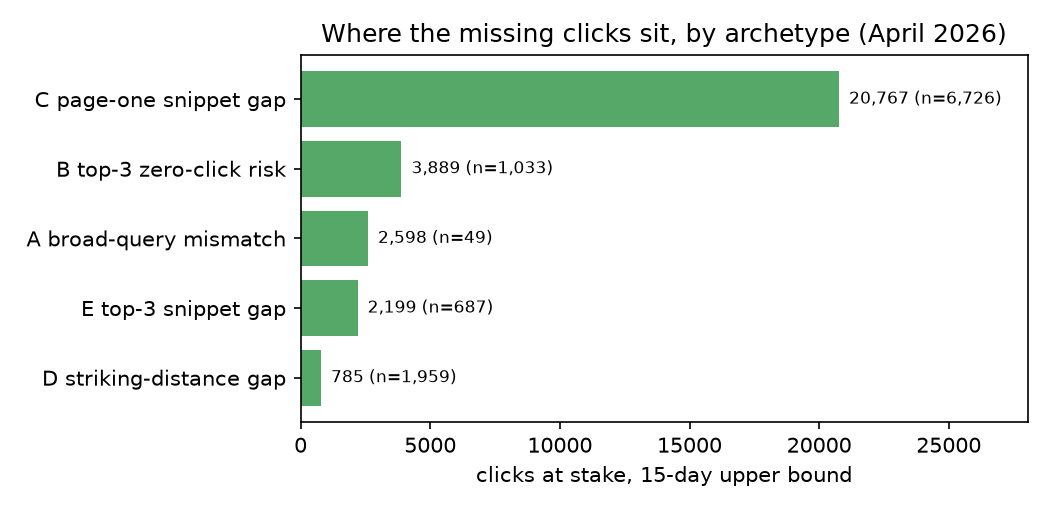

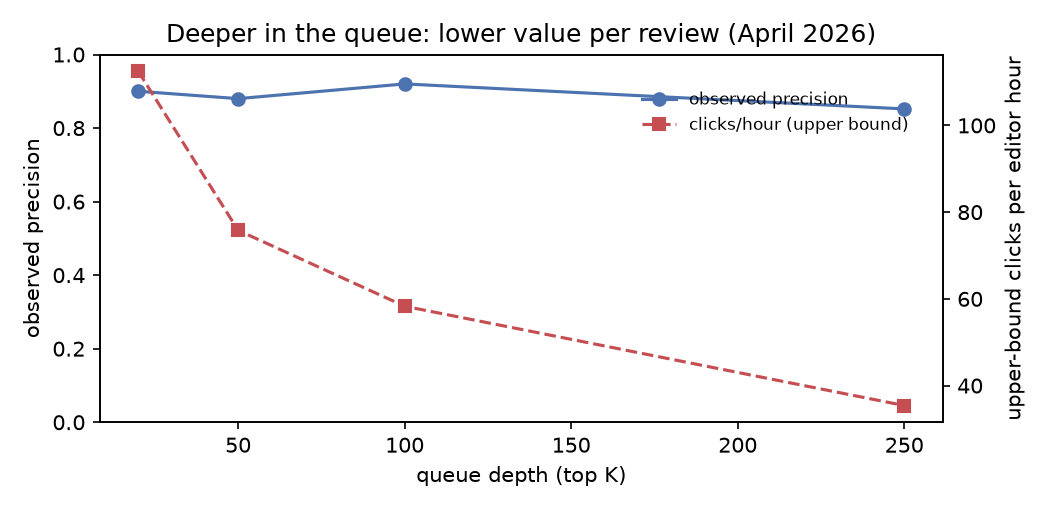

In [6]:
cols = ["rank", "content_hash_id", "client_hash_id", "archetype", "reason_code", "action", "human_check", "automate",
        "content_type", "main_intent", "pos_bucket", "pos_f", "impr_f", "clicks_f", "ctr_f", "expected_ctr",
        "clicks_at_stake", "model_prob", "second_opinion"]
queue[cols].round(4).to_csv("work/outputs/w07_action_queue.csv", index=False)

# Figure: clicks at stake by archetype
arch = queue[queue["rule_flag"]].groupby("archetype")["clicks_at_stake"].agg(["sum", "size"]).sort_values("sum")
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(arch.index, arch["sum"], color="#55A868")
for i, (s, n) in enumerate(zip(arch["sum"], arch["size"])):
    ax.text(s, i, f"  {s:,.0f} (n={n:,})", va="center", fontsize=8)
ax.set_xlabel("clicks at stake, 15-day upper bound"); ax.set_title("Where the missing clicks sit, by archetype (April 2026)")
ax.set_xlim(0, arch["sum"].max() * 1.35); fig.tight_layout(); fig.savefig("work/figures/w07_archetype_clicks.png", dpi=150); plt.close(fig)

# Figure: observed precision and value per hour by queue depth
fig, ax1 = plt.subplots(figsize=(7, 3.4))
ax1.plot(cv["top_k"], cv["observed precision"], "o-", color="#4C72B0", label="observed precision")
ax1.set_xlabel("queue depth (top K)"); ax1.set_ylabel("observed precision"); ax1.set_ylim(0, 1)
ax2 = ax1.twinx(); ax2.plot(cv["top_k"], cv["upper-bound clicks per editor hour"], "s--", color="#C44E52", label="clicks/hour (upper bound)")
ax2.set_ylabel("upper-bound clicks per editor hour"); ax1.set_title("Deeper in the queue: lower value per review (April 2026)")
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.85), frameon=False, fontsize=8); fig.tight_layout()
fig.savefig("work/figures/w07_precision_by_depth.png", dpi=150); plt.close(fig)

receipts = {"decision_day": "2026-04-16", "features": "1-15 Apr 2026", "rule": "Week-4 frozen (impr_f>=500, ctr < 0.5 x bucket median)",
            "second_opinion": "RandomForest trained on March 2026 (ML-08 settings)", "seed": SEED, "sklearn": sklearn.__version__,
            "queue_rows": int(len(queue)), "rule_flagged": int(queue["rule_flag"].sum()),
            "archetypes": summary.reset_index().round(3).to_dict(orient="records"),
            "cost_value": cv.to_dict(orient="records"), "decay_by_age": decay.reset_index().astype({"age_bucket": str}).round(4).to_dict(orient="records"),
            "monitoring_run": monitor, "triggers": {k: bool(v) for k, v in TRIG.items()}}
with open("work/outputs/w07_playbook_metrics.json", "w") as fh:
    json.dump(receipts, fh, indent=2, default=str)
for f in ["work/outputs/w07_action_queue.csv", "work/outputs/w07_playbook_metrics.json", "work/figures/w07_decay_by_age.png",
          "work/figures/w07_archetype_clicks.png", "work/figures/w07_precision_by_depth.png"]:
    print(f"wrote {f} ({os.path.getsize(f)/1024:.0f} KB)")
display(Image("work/figures/w07_archetype_clicks.png")); display(Image("work/figures/w07_precision_by_depth.png"))


## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.